In [1]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Un modello semplice di attivazione e propagazione elettrica nel cuore

In questo esempio costruiamo un modello di propagazione elettrica nel tessuto cardiaco.

- consideriamo una piccola porzione di tessuto cardiaco
- rappresentiamo il tessuto con un insieme di punti nel piano
- scegliamo un sito di pacing $P$, cioè il punto in cui viene applicato lo stimolo elettrico
- supponiamo che il segnale si propaghi in tutte le direzioni con velocità costante $v$
- per ogni punto $X_i$, il tempo di attivazione è

$$
t_i = \frac{d(X_i,P)}{v}.
$$

Quindi i punti più vicini allo stimolo si attivano prima, quelli più lontani dopo.

## Costruiamo una regione nel piano
Supponiamo di estrarre dal cuore un patch di tessuto.

Numero di punti: 2501


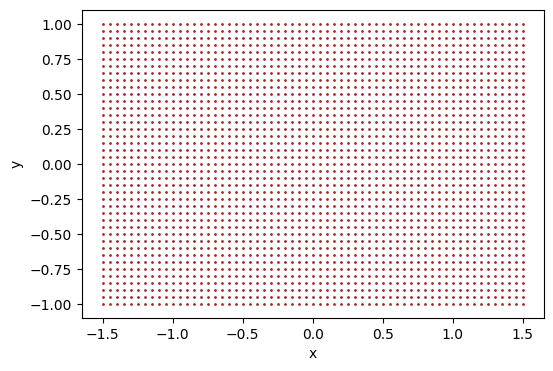

In [ ]:
x = np.linspace(-1.5, 1.5, 61)
y = np.linspace(-1, 1, 41)
X, Y = np.meshgrid(x, y)
points = np.column_stack((X.ravel(), Y.ravel()))

print("Numero di punti:", len(points))

plt.figure(figsize=(5, 4))
plt.scatter(points[:, 0], points[:, 1], s=4, marker=".", color="brown")

plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## Scegliamo un sito di pacing
Supponiamo di stimolare il tessuto nel punto $P=(-0.25,-0.75)$. Il segnale si propaga a velocità costante $v$.

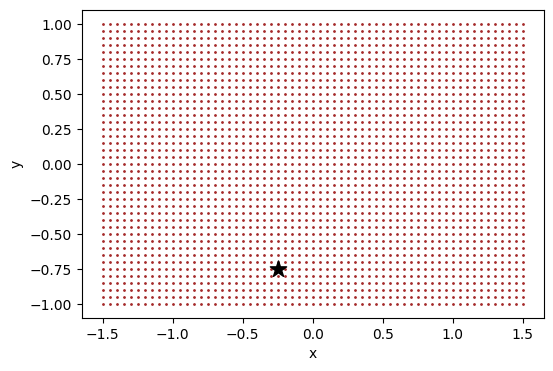

In [ ]:
pacing_site = np.array([-0.25, -0.75])

plt.figure(figsize=(5, 4))
plt.scatter(points[:, 0], points[:, 1], s=4, marker=".", color="brown")
plt.scatter(pacing_site[0], pacing_site[1], s=150, marker="*", label="Stimolo", color="black")
plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## Distanza dal sito di pacing

Per ogni punto $X_i$ del tessuto calcoliamo la distanza dal sito di pacing $P$.

Se
$$
X_i=(x_i,y_i)
$$
e
$$
P=(x_P,y_P),
$$
la distanza euclidea tra i due punti è
$$
d(X_i,P)=\sqrt{(x_i-x_P)^2+(y_i-y_P)^2}.
$$

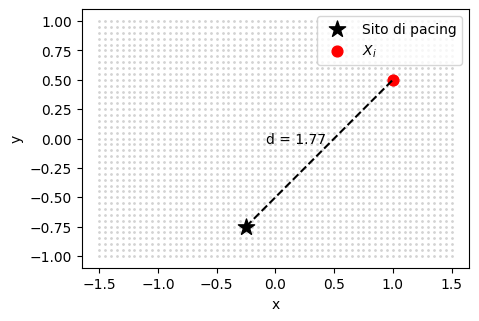

In [115]:
# Scegliamo un punto del tessuto
target = np.array([1.0, 0.5])
i = np.argmin(np.linalg.norm(points - target, axis=1))
point = points[i]

distance = np.linalg.norm(point - pacing_site)

plt.figure(figsize=(5, 4))
plt.scatter(points[:, 0], points[:, 1], s=4, marker=".", color="lightgray")
plt.scatter(pacing_site[0], pacing_site[1], s=150, marker="*", color="black", label="Sito di pacing")
plt.scatter(point[0], point[1], s=60, color="red", label=r"$X_i$")
plt.plot([pacing_site[0], point[0]], [pacing_site[1], point[1]], "--", color="black")

midpoint = (pacing_site + point) / 2
plt.text(midpoint[0]-0.2, midpoint[1] + 0.08, f"d = {distance:.2f}", ha="center")

plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

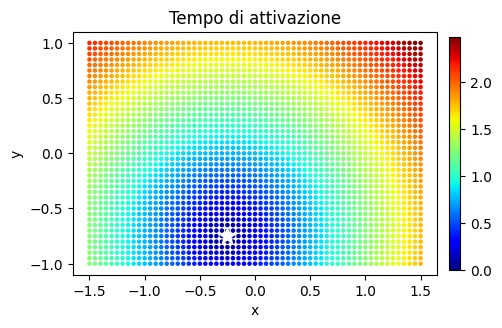

In [110]:
v = 1.0

distances = np.linalg.norm(points - pacing_site, axis=1)
activation_time = distances / v

plt.figure(figsize=(5, 4))
sc = plt.scatter(points[:, 0], points[:, 1], c=activation_time, s=20, marker=".", cmap="jet")
plt.scatter(pacing_site[0], pacing_site[1], s=150, marker="*", label="Stimolo", color="w")
plt.gca().set_aspect("equal")
plt.colorbar(sc, fraction=0.03, pad=0.03)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Tempo di attivazione")

plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(points[:, 0], points[:, 1], s=4, marker=".", color="brown", alpha=0.15)
activated = ax.scatter([], [], s=20, marker=".")
ax.scatter(pacing_site[0], pacing_site[1], s=150, marker="*", label="Stimolo", color="black")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")

max_time = activation_time.max()
frames = np.linspace(0, max_time, 50)

def update(frame):
    active = activation_time <= frame
    activated.set_offsets(points[active])
    ax.set_title(f"t = {frame:.2f}")
    return activated,

animation = FuncAnimation(fig, update, frames=frames, interval=80, blit=False)

plt.close()
HTML(animation.to_jshtml())

##  Cosa succede se spostiamo il punto di pacing?

Il modello non cambia: cambia soltanto la distanza di ogni punto dal nuovo sito di pacing.

Confrontiamo due posizioni diverse.

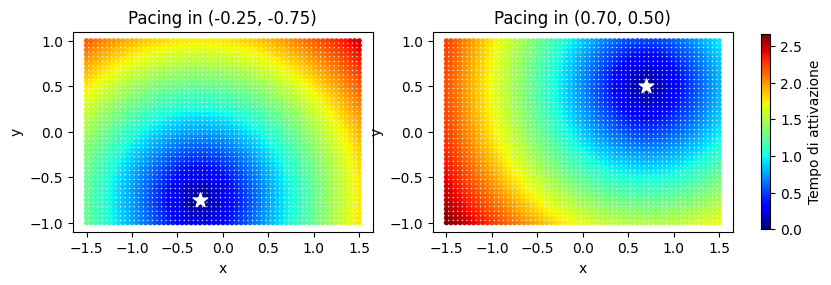

In [ ]:
sites = [np.array([-0.25, -0.75]), np.array([0.7, 0.5])]
times_list = [np.linalg.norm(points - site, axis=1) / v for site in sites]
vmax = max(times.max() for times in times_list)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

for a, site, times in zip(ax, sites, times_list):

    sc = a.scatter(points[:, 0], points[:, 1], c=times, s=8, cmap="jet", vmin=0, vmax=vmax)
    a.scatter(site[0], site[1], s=120, marker="*", color="w")

    a.set_aspect("equal")
    a.set_xlabel("x")
    a.set_ylabel("y")
    a.set_title(f"Pacing in ({site[0]:.2f}, {site[1]:.2f})")

fig.colorbar(sc, ax=ax, fraction=0.014, pad=0.04, label="Tempo di attivazione")
plt.show()

## Due siti di pacing

Supponiamo ora di fare pacing contemporaneamente da due punti $P_1$ e $P_2$.

Ogni punto del tessuto viene raggiunto dal fronte che arriva per primo.

Quindi il tempo di attivazione è

$$
t_i=
\frac{
\min\left(
d(X_i,P_1),
d(X_i,P_2)
\right)
}{v}.
$$

In altre parole: per ogni punto scegliamo semplicemente la distanza dal sito di pacing più vicino.

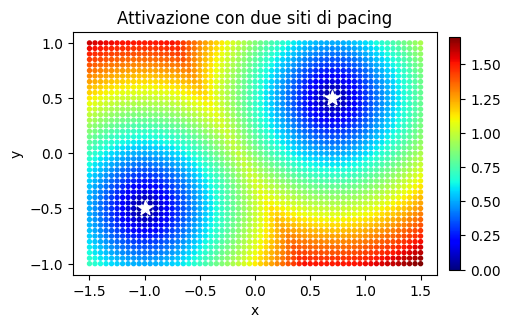

In [111]:
pacing_site_1 = np.array([-1, -0.5])
pacing_site_2 = np.array([0.7, 0.5])

d1 = np.linalg.norm(points - pacing_site_1, axis=1)
d2 = np.linalg.norm(points - pacing_site_2, axis=1)

activation_time_two_sites = np.minimum(d1, d2) / v

plt.figure(figsize=(5, 4))

sc = plt.scatter(points[:, 0], points[:, 1], c=activation_time_two_sites, s=8,  cmap="jet")

plt.scatter([pacing_site_1[0], pacing_site_2[0]], [pacing_site_1[1], pacing_site_2[1]], s=120, marker="*", label="Stimoli", color="w")

plt.colorbar(sc, fraction=0.03, pad=0.03)
plt.gca().set_aspect("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Attivazione con due siti di pacing")
plt.show()

### Confronto

Possiamo confrontare anche il tempo necessario per attivare tutto il tessuto nei due casi.
Aggiungendo un secondo punto di pacing, il tempo necessario ad attivare tutto il tessuto aumenta o diminuisce?

In [ ]:
single_site_total = activation_time.max()
two_sites_total = activation_time_two_sites.max()

print(f"Un sito di pacing:  {single_site_total:.2f}")
print(f"Due siti di pacing: {two_sites_total:.2f}")

Un sito di stimolazione:  2.47
Due siti di stimolazione: 1.70


Vediamo due fronti di attivazione che partono contemporaneamente e si incontrano.

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(points[:, 0], points[:, 1], s=4, marker=".", color="brown", alpha=0.15)
activated = ax.scatter([], [], s=20, marker=".")
ax.scatter([pacing_site_1[0], pacing_site_2[0]],[pacing_site_1[1], pacing_site_2[1]], s=150, marker="*", label="Stimoli", color="black")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")

max_time_two = activation_time_two_sites.max()
frames = np.linspace(0, max_time_two, 50)

def update_two_sites(frame):
    active = activation_time_two_sites <= frame
    activated.set_offsets(points[active])
    ax.set_title(f"t = {frame:.2f}")
    return activated,

animation_two = FuncAnimation(fig, update_two_sites, frames=frames, interval=80, blit=False)

plt.close()
HTML(animation_two.to_jshtml())

## Conclusione

In questo esempio abbiamo usato soltanto:

- punti e coordinate
- distanza tra punti
- una velocità di propagazione
- il minimo tra due distanze

e siamo riusciti a costruire una piccola simulazione di propagazione.

Nei modelli cardiaci reali la geometria è tridimensionale e la propagazione dipende anche dalla struttura del tessuto e dall'orientamento delle fibre, ma l'idea generale rimane la stessa:

**trasformare un problema fisico in un modello matematico che il computer possa risolvere.**